<a href="https://colab.research.google.com/github/isurika23/EN4554_Deep-Learning-for-Vision/blob/main/EN4554_Assignment02_CNN/EN4554_Assignment02_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 Assignment 2 on CNNs
Gunasekara T I U (220192J) <br/>
[Github](https://github.com/isurika23/EN4554_Deep-Learning-for-Vision.git) <br/>
Submitted Date: 22/10/2026 <br/>
Acknowledgement: I have used [Claude](https://claude.ai/new) to help with the coding


---




# Setup


## Imports and Seeds

In [18]:
import os
import random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

# fix random seeds
def set_seed(seed=42):
    random.seed(seed);
    np.random.seed(seed)
    torch.manual_seed(seed);
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


#  Dataset destination
Option 1: Google drive (Google Colab)

In [19]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/EN4554_A2'
NUM_WORKERS = 2

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Option 2: root (Local machine) *-- currently commented*

In [20]:
# PROJECT_DIR = '.'          # folder where this notebook lives
# NUM_WORKERS = 2            # on Windows, set to 0 if the DataLoader hangs or errors

In [21]:
DATA_ROOT   = os.path.join(PROJECT_DIR, 'data')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')   # save losses/accuracies here later
os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Data:", DATA_ROOT, "| Results:", RESULTS_DIR)

Data: /content/drive/MyDrive/EN4554_A2/data | Results: /content/drive/MyDrive/EN4554_A2/results


Dataset: CIFAR-10 (torchvision.datasets.CIFAR10) <br/>
Training set: 45k | Validation set: 5k

## Download the dataset - `CIFAR-10`

In [22]:
raw = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, download=True)

## Split 45k/5k and compute statistics

In [23]:
g = torch.Generator().manual_seed(42)
perm = torch.randperm(50000, generator=g)
train_idx = perm[:45000].tolist()
val_idx   = perm[45000:].tolist()

# Per-channel statistics from the TRAINING split only
x = torch.tensor(raw.data[train_idx]).float() / 255.0   # shape (45000, 32, 32, 3)
mean = x.mean(dim=(0, 1, 2))
std  = x.std(dim=(0, 1, 2))
print("mean:", mean, "std:", std)

mean: tensor([0.4917, 0.4823, 0.4467]) std: tensor([0.2471, 0.2435, 0.2616])


## A reusable loader function

In [24]:
normalize = T.Normalize(mean.tolist(), std.tolist())
base_tf = T.Compose([T.ToTensor(), normalize])

def get_loaders(train_tf=base_tf, batch_size=128, n_train=None):
    # Two dataset objects, so augmentation applies to train only, never to val
    train_set = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=train_tf)
    val_set   = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=base_tf)
    idx = train_idx if n_train is None else train_idx[:n_train]
    train_loader = DataLoader(Subset(train_set, idx), batch_size=batch_size, shuffle=True,
                              num_workers=NUM_WORKERS, generator=torch.Generator().manual_seed(42))
    val_loader = DataLoader(Subset(val_set, val_idx), batch_size=512,
                            shuffle=False, num_workers=NUM_WORKERS)
    return train_loader, val_loader

## Sanity check

torch.Size([128, 3, 32, 32]) torch.Size([128])
mean: tensor([ 0.0016, -0.0306, -0.0233]), std: tensor([0.9923, 0.9767, 0.9602])


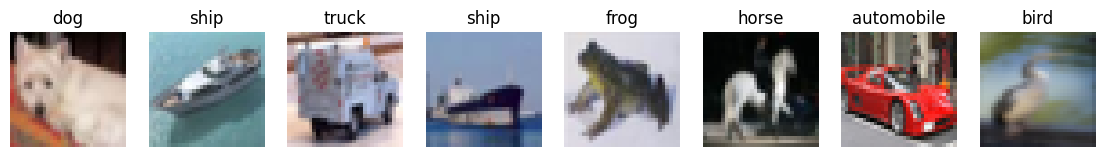

In [25]:
train_loader, val_loader = get_loaders()
xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)                         # expect [128, 3, 32, 32] and [128]
print(f'mean: {xb.mean(dim=(0, 2, 3))}, std: {xb.std(dim=(0, 2, 3))}')  # should be close to 0 and 1

classes = raw.classes
imgs = xb[:8] * std.view(3, 1, 1) + mean.view(3, 1, 1)   # undo normalization for display
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, img, lbl in zip(axes, imgs, yb[:8]):
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1)); ax.set_title(classes[lbl]); ax.axis('off')
plt.show()

# Task 01: Backpropogation
(a) Implement Linear, ReLU, and softmax cross-entropy with explicit `forward/backward` (no `autograd`), and assemble an MLP.<br/>


(b) Verify your gradients against `autograd` and against centred finite differences; report the relative errors. Use `torch`. allclose to check whether the gradients match. <br/>


(c) Train it with SGD on flattened `CIFAR-10` images; plot the loss and report validation accuracy. <br/>


(d) For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU. Explain.


## (a) Linear, ReLU, Softmax cross entropy, Sigmoid Implementations

In [26]:
class Linear:
    def __init__(self, in_f, out_f, dtype=torch.float32):
        # He (Kaiming) init: std = sqrt(2 / fan_in)
        self.W = torch.randn(out_f, in_f, device=device, dtype=dtype) * (2.0 / in_f) ** 0.5
        self.b = torch.zeros(out_f, device=device, dtype=dtype)
        self.dW, self.db = None, None

    def forward(self, x):
        self.x = x                     # cache the input: backward needs it
        return x @ self.W.T + self.b   # Y = X W^T + b

    def backward(self, dout):
        self.dW = dout.T @ self.x      # shape (out, in). dout is (N, out), self.x is (N, in)
        self.db = dout.sum(dim=0)
        return dout @ self.W           # dL/dX, shape (N, in)

class ReLU:
    def forward(self, x):
        self.mask = x > 0              # boolean mask of where x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)   # σ' = σ(1-σ)


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        N = logits.shape[0]
        shifted = logits - logits.max(dim=1, keepdim=True).values   # numerical stability
        exp = shifted.exp()
        sum_exp = exp.sum(dim=1, keepdim=True)
        self.probs = exp / sum_exp                                  # softmax probabilities, shape (N, 10)
        self.y = y
        log_probs = shifted - sum_exp.log()                         # log softmax = shifted - log(sum of exp)
        return -log_probs[torch.arange(N, device=logits.device), y].mean()  # mean over the batch of -log_probs at the true class

    def backward(self):
        N = self.probs.shape[0]
        d = self.probs.clone()
        d[torch.arange(N, device=d.device), self.y] -= 1   # p - onehot(y)
        return d / N                                        # /N because the loss is a mean shape (N, 10)


class MLP:
    def __init__(self, sizes, act=ReLU, dtype=torch.float32):
        # sizes = [3072, 512, 256, 10] -> Linear, act, Linear, act, Linear
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], dtype))
            if i < len(sizes) - 2:     # no activation after the last layer
                self.layers.append(act())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        # pass x through every layer, return logits
        for layer in self.layers:
          x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        # start from loss_fn.backward(), go through layers in REVERSE
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)

    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def sgd_step(self, lr):
        # W -= lr * dW and b -= lr * db for every Linear
        for l in self.linears():
            l.W -= lr * l.dW
            l.b -= lr * l.db

## (b) Gradient check

### Centered Finite Difference (FD): `numerical_grad`<br/>
Adds a tiny number $\epsilon$ (eps=1e-6), calculates the forward pass to get a new loss ($L_+$), subtracts $\epsilon$ to get another loss ($L_-$), and calculates the slope using the formula $\frac{L_+ - L_-}{2\epsilon}$ for each $P_i$.

### `autograd` (AG):
The block labeled `(2) Autograd reference` sets up a parallel network using standard PyTorch operations with requires_grad=True. When `F.cross_entropy(h, y).backward()` is called, PyTorch's Autograd automatically traverses the computational graph backward to calculate the exact chain-rule gradients, storing them in W.grad and b.grad.

In [27]:
def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-12)).item()

def numerical_grad(net, x, y, P, eps=1e-6):
    G = torch.zeros_like(P)
    flatP, flatG = P.view(-1), G.view(-1)   # views share memory, so editing flatP edits P
    for i in range(flatP.numel()):
        old = flatP[i].item()
        flatP[i] = old + eps
        L_plus  = net.loss(x, y).item()
        flatP[i] = old - eps
        L_minus = net.loss(x, y).item()
        flatP[i] = old
        flatG[i] = (L_plus - L_minus) / (2 * eps)
    return G

def grad_check(act):
    torch.manual_seed(0)
    dt = torch.float64                       # float64 so finite differences are accurate
    net = MLP([20, 16, 16, 10], act=act, dtype=dt)
    x = torch.randn(8, 20, device=device, dtype=dt)
    y = torch.randint(0, 10, (8,), device=device)

    # (1) Our manual gradients
    net.loss(x,y)
    net.backward()

    # (2) Autograd reference: same weights, standard PyTorch ops
    torch_act = {ReLU: torch.relu, Sigmoid: torch.sigmoid}[act]
    lins = net.linears()
    Ws = [l.W.clone().requires_grad_(True) for l in lins]
    bs = [l.b.clone().requires_grad_(True) for l in lins]
    h = x
    for i, (W, b) in enumerate(zip(Ws, bs)):
        h = h @ W.T + b
        if i < len(lins) - 1:
            h = torch_act(h)
    F.cross_entropy(h, y).backward()

    print(f"\n--- {act.__name__} ---")
    print(f"{'param':<7}{'rel err vs autograd':>21}{'rel err vs FD':>16}{'allclose AG':>13}{'allclose FD':>13}")
    for i, l in enumerate(lins):
        for name, P, G, G_ag in [(f"W{i+1}", l.W, l.dW, Ws[i].grad),
                                 (f"b{i+1}", l.b, l.db, bs[i].grad)]:
            G_fd = numerical_grad(net, x, y, P)
            print(f"{name:<7}{rel_err(G, G_ag):>21.2e}{rel_err(G, G_fd):>16.2e}"
                  f"{str(torch.allclose(G, G_ag)):>13}"
                  f"{str(torch.allclose(G, G_fd, rtol=1e-4, atol=1e-6)):>13}")

grad_check(ReLU)
grad_check(Sigmoid)


--- ReLU ---
param    rel err vs autograd   rel err vs FD  allclose AG  allclose FD
W1                  1.12e-16        7.51e-10         True         True
b1                  9.17e-17        9.97e-10         True         True
W2                  4.79e-17        5.64e-10         True         True
b2                  6.10e-17        6.53e-10         True         True
W3                  4.52e-17        8.02e-10         True         True
b3                  6.91e-17        4.74e-10         True         True

--- Sigmoid ---
param    rel err vs autograd   rel err vs FD  allclose AG  allclose FD
W1                  1.17e-16        8.09e-09         True         True
b1                  7.69e-17        3.70e-09         True         True
W2                  6.11e-17        2.24e-09         True         True
b2                  7.27e-17        7.29e-10         True         True
W3                  5.54e-17        9.05e-10         True         True
b3                  6.82e-17        4.27e-10  

## (c) Train with SGD

In [28]:
def evaluate(net, loader):
    loss_sum, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb = xb.to(device).view(xb.size(0), -1)      # flatten (B,3,32,32) -> (B,3072)
        yb = yb.to(device)
        logits = net.forward(xb)
        loss_sum += net.loss_fn.forward(logits, yb).item() * len(yb)
        correct  += (logits.argmax(dim=1) == yb).sum().item()
        total    += len(yb)
    return loss_sum / total, correct / total

hist_path = os.path.join(RESULTS_DIR, 'task1c_history.pt')
if os.path.exists(hist_path):
    history = torch.load(hist_path)
    print("Loaded saved Task 1(c) results")
else:
  set_seed(42)
  train_loader, val_loader = get_loaders(batch_size=128)
  net = MLP([3072, 512, 256, 10], act=ReLU)
  lr, epochs = 0.05, 10
  history = {'iter_loss': [], 'train_loss': [], 'val_loss': [], 'val_acc': []}

  for ep in range(epochs):
      run_loss, n = 0.0, 0
      for xb, yb in train_loader:
          xb = xb.to(device).view(xb.size(0), -1); yb = yb.to(device)
          loss = net.loss(xb, yb)   # forward + loss
          net.backward()            # backward
          net.sgd_step(lr)          # SGD step
          history['iter_loss'].append(loss.item())
          run_loss += loss.item() * len(yb); n += len(yb)
      val_loss, val_acc = evaluate(net, val_loader)
      history['train_loss'].append(run_loss / n)
      history['val_loss'].append(val_loss); history['val_acc'].append(val_acc)
      print(f"epoch {ep+1:2d} | train loss {run_loss/n:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.3f}")

  torch.save(history, os.path.join(RESULTS_DIR, 'task1c_history.pt'))

Loaded saved Task 1(c) results


## Plotting

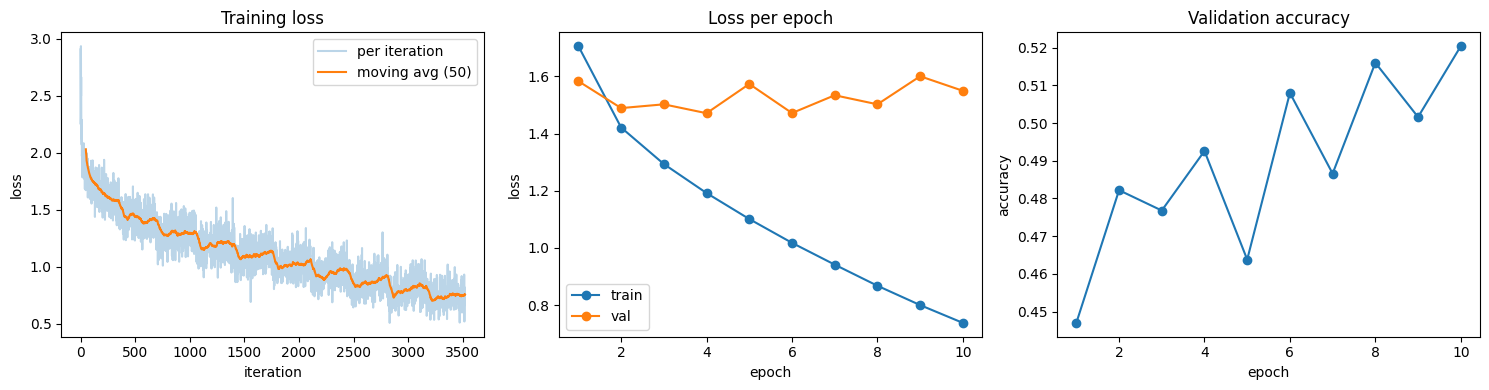

Final validation accuracy: 0.5204


In [29]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(history['iter_loss'], alpha=0.3, label='per iteration')
k = 50
smooth = np.convolve(history['iter_loss'], np.ones(k) / k, mode='valid')
ax[0].plot(range(k - 1, len(history['iter_loss'])), smooth, label=f'moving avg ({k})')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss'); ax[0].legend(); ax[0].set_title('Training loss')
ep = range(1, len(history['train_loss']) + 1)
ax[1].plot(ep, history['train_loss'], 'o-', label='train'); ax[1].plot(ep, history['val_loss'], 'o-', label='val')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('loss'); ax[1].legend(); ax[1].set_title('Loss per epoch')
ax[2].plot(ep, history['val_acc'], 'o-'); ax[2].set_xlabel('epoch'); ax[2].set_ylabel('accuracy')
ax[2].set_title('Validation accuracy')
plt.tight_layout(); plt.show()
print(f"Final validation accuracy: {history['val_acc'][-1]:.4f}")

#### Plots and results interpretation:
Even though the training loss is gradually decreased, the validation error and accuracy keeps fluctuating while the gap between the training and validation error keeps getting increased. This shows the overfitting of the model for the training data set rather than actually learning. With about 1.7M parameters and no regularization, the network can memorize the training images instead of learning features that generalize. The validation accuracy fluctuates because the validation set has only 5k images and the model is no longer improving consistently on unseen data.

Also the validation accurary tops at 52%, which is a comparatively low accuracy. We can argue that the reason for this is flattening of the input data, which removes the spatial details of the input.

## (d) Per-layer gradient norms at initialization

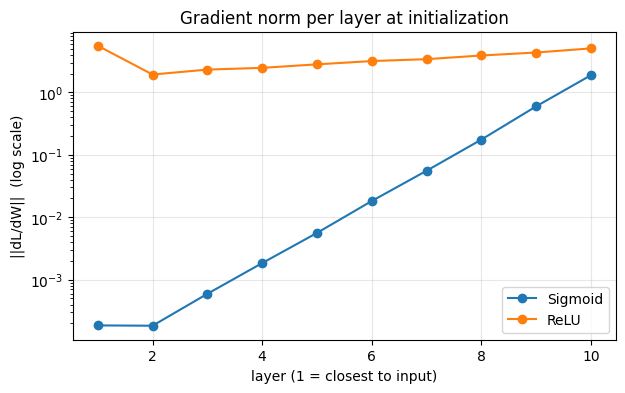

Sigmoid ['1.9e-04', '1.8e-04', '5.9e-04', '1.8e-03', '5.6e-03', '1.8e-02', '5.6e-02', '1.8e-01', '6.0e-01', '1.9e+00']
ReLU ['5.6e+00', '1.9e+00', '2.3e+00', '2.5e+00', '2.8e+00', '3.2e+00', '3.4e+00', '3.9e+00', '4.4e+00', '5.1e+00']


In [30]:
xb, yb = next(iter(train_loader))
xb = xb.to(device).view(xb.size(0), -1); yb = yb.to(device)
sizes = [3072] + [256] * 9 + [10]          # 10 Linear layers

norms = {}
for act in [Sigmoid, ReLU]:
    set_seed(42)                           # identical initial weights for both
    net = MLP(sizes, act=act)
    # one forward (loss) and one backward pass, NO update
    net.loss(xb, yb)
    net.backward()
    norms[act.__name__] = [l.dW.norm().item() for l in net.linears()]   # list of dW.norm() for each Linear layer

plt.figure(figsize=(7, 4))
for name, v in norms.items():
    plt.semilogy(range(1, 11), v, 'o-', label=name)
plt.xlabel('layer (1 = closest to input)'); plt.ylabel('||dL/dW||  (log scale)')
plt.title('Gradient norm per layer at initialization'); plt.legend(); plt.grid(alpha=0.3)
plt.show()
for name, v in norms.items():
    print(name, ['%.1e' % g for g in v])

#### Interpretation:
**Sigmoid:** the norm falls from 2.2 at layer 10 to 1.9e-4 at layer 1, a drop of about 10,000x. Going backward, each layer's gradient is multiplied by the sigmoid derivative (at most 0.25) and by Wᵀ. The numbers show a drop of roughly 3x per layer, and ten layers of that compounds. So layer 1 learns about ten thousand times more slowly than layer 10 at the same learning rate, causing the **vanishing gradient problem**.

**ReLU:** the norms stay between about 1.7 and 5.3, the same order of magnitude across all layers. ReLU's derivative is exactly 1 for active neurons, and He initialization keeps the signal's scale stable, so nothing shrinks as it flows back.

# Task 02 - Optimizers
(a) Implement SGD with momentum and Adam (with bias correction) as torch.optim.Optimizer subclasses. Show that they match torch.optim.SGD and torch.optim.Adam.<br/>


(b) On f (x, y) =12 (x2 +50 y2), plot the trajectories of SGD, SGD with momentum, and Adam. Use contour to plot the contours of f (x, y) Explain the differences.<br/>


(c) Train a small CNN with each optimizer (plain SGD, SGD with momentum, Adam) at three learning rates each. Plot validation accuracy versus learning rate and the training loss at the best rate. Discuss sensitivity.

### Optimization Algorithms

#### 1. Stochastic Gradient Descent (SGD)
Steps in the direction of the local steepest descent (negative gradient).

**Equations:**
$$g_t = \nabla f(x_t)$$
$$x_{t+1} = x_t - \eta g_t$$

*   $g_t$: Gradient at timestep $t$
*   $\eta$: Learning rate

<br/>

#### 2. SGD with Momentum
Builds up "velocity" using a running mean of past gradients. Accelerates movement in consistent directions and dampens zig-zagging.

**Equations:**
$$v_{t+1} = \rho v_t + \nabla f(x_t)$$
$$x_{t+1} = x_t - \eta v_{t+1}$$

*   $v_t$: Velocity (momentum)
*   $\rho$: Friction factor (typically $0.9$ or $0.99$)

<br/>

#### 3. Adam (Adaptive Moment Estimation)
Creates per-parameter learning rates by tracking both the average gradient and the average squared gradient. Includes bias correction to fix early estimates starting at zero.

**Equations:**

*1. Moving Averages (Moments):*
$$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$$
$$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$

*2. Bias Correction:*
$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}$$
$$\hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$

*3. Parameter Update:*
$$\theta_t = \theta_{t-1} - \alpha \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$$

*   $m_t, v_t$: First and second moment estimates
*   $\beta_1, \beta_2$: Exponential decay rates (Defaults: $0.9, 0.999$)
*   $\alpha$: Step size / Learning rate (Default: $0.001$)
*   $\epsilon$: Small constant for numerical stability (Default: $10^{-8}$)

## (a) Implement custom optimizers

In [31]:
import copy

class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0, weight_decay=0.0):
        defaults = dict(lr=lr, momentum=momentum, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group['lr'], group['momentum'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)          # L2 penalty: g + wd * p
                if mu != 0:
                    state = self.state[p]
                    if 'buf' not in state:
                        state['buf'] = torch.zeros_like(p)
                    buf = state['buf']
                    buf.mul_(mu).add_(g)            # momentum: buf = mu * buf + g
                    g = buf
                p.add_(g, alpha=-lr)
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group['lr'], group['betas'], group['eps'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                state = self.state[p]
                if len(state) == 0:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                t, m, v = state['t'], state['m'], state['v']
                m.mul_(b1).add_(g, alpha=1 - b1)          # update m in place: m = b1 * m + (1 - b1) * g
                v.mul_(b2).addcmul_(g, g, value=1 - b2)   # update v in place: v = b2 * v + (1 - b2) * g^2
                # bias-corrected m_hat and v_hat
                m_hat = m / (1 - b1 ** t)
                v_hat = v / (1 - b2 ** t)
                # update p: p = p - lr * m_hat / (sqrt(v_hat) + eps)
                p.sub_(lr * m_hat / (v_hat.sqrt() + eps))
        return loss

### Check against `torch.optim.SGD` and `torch.optim.Adam`

In [32]:
def compare(make_mine, make_ref, steps=50):
    torch.manual_seed(0)
    model_a = nn.Sequential(nn.Linear(20, 32), nn.ReLU(), nn.Linear(32, 10)).double().to(device)
    model_b = copy.deepcopy(model_a)                       # identical starting weights
    opt_a, opt_b = make_mine(model_a.parameters()), make_ref(model_b.parameters())
    g = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 20, generator=g, dtype=torch.float64).to(device)
        y = torch.randint(0, 10, (64,), generator=g).to(device)
        for model, opt in [(model_a, opt_a), (model_b, opt_b)]:
            # zero_grad, cross-entropy loss, backward, step
            opt.zero_grad()
            F.cross_entropy(model(x), y).backward()
            opt.step()

    max_diff = max((pa - pb).abs().max().item()
                   for pa, pb in zip(model_a.parameters(), model_b.parameters()))
    same = all(torch.allclose(pa, pb) for pa, pb in zip(model_a.parameters(), model_b.parameters()))
    return max_diff, same

tests = {
    'SGD':            (lambda ps: MySGD(ps, lr=0.1),                  lambda ps: torch.optim.SGD(ps, lr=0.1)),
    'SGD + momentum': (lambda ps: MySGD(ps, lr=0.1, momentum=0.9),    lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9)),
    'SGD + mom + wd': (lambda ps: MySGD(ps, lr=0.1, momentum=0.9, weight_decay=5e-4),
                       lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9, weight_decay=5e-4)),
    'Adam':           (lambda ps: MyAdam(ps, lr=1e-3),                lambda ps: torch.optim.Adam(ps, lr=1e-3)),
    'Adam + wd':      (lambda ps: MyAdam(ps, lr=1e-3, weight_decay=5e-4),
                       lambda ps: torch.optim.Adam(ps, lr=1e-3, weight_decay=5e-4)),
}
print(f"{'optimizer':<21}{'| max(abs(diff)) after 50 steps |':>15}{'allclose':>10}")
for name, (mine, ref) in tests.items():
    d, s = compare(mine, ref)
    print(f"{name:<20}{d:>14.2e}{str(s):>30}")

optimizer            | max(abs(diff)) after 50 steps |  allclose
SGD                       0.00e+00                          True
SGD + momentum            0.00e+00                          True
SGD + mom + wd            0.00e+00                          True
Adam                      5.55e-17                          True
Adam + wd                 5.55e-17                          True


## (b) Trajectories on $$f(x, y) = \frac{1}{2}(x^2 + 50y^2)$$


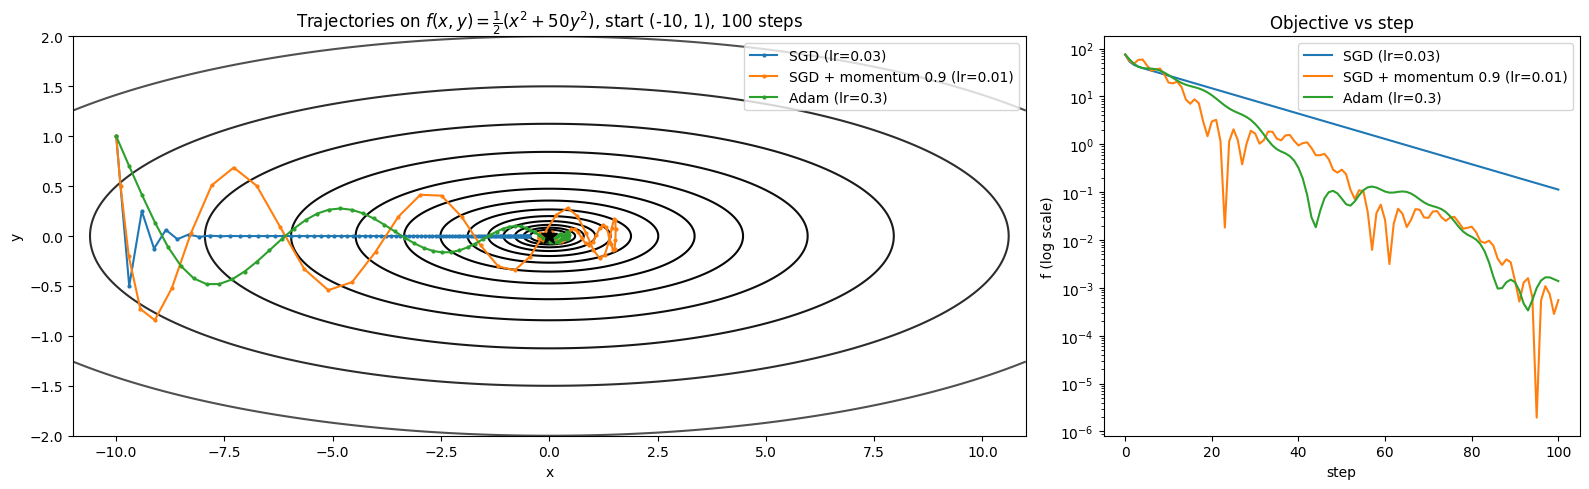

SGD (lr=0.03)                  final point (-0.4755, +0.0000)  f = 1.13e-01
SGD + momentum 0.9 (lr=0.01)   final point (+0.0263, +0.0029)  f = 5.56e-04
Adam (lr=0.3)                  final point (-0.0513, -0.0016)  f = 1.38e-03


In [33]:
def f_quad(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def trajectory(make_opt, start=(-10.0, 1.0), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([p])
    path = [p.detach().clone()]
    for _ in range(steps):
        # zero_grad, compute f_quad(p), backward, step
        opt.zero_grad()
        f_quad(p).backward()
        opt.step()
        path.append(p.detach().clone())
    return torch.stack(path).numpy()

configs = {
    'SGD (lr=0.03)':                lambda ps: MySGD(ps, lr=0.03),
    'SGD + momentum 0.9 (lr=0.01)': lambda ps: MySGD(ps, lr=0.01, momentum=0.9),
    'Adam (lr=0.3)':                lambda ps: MyAdam(ps, lr=0.3),
}
paths = {name: trajectory(make) for name, make in configs.items()}

X, Y = np.meshgrid(np.linspace(-11, 11, 400), np.linspace(-2, 2, 400))
Z = 0.5 * (X ** 2 + 50 * Y ** 2)
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [2, 1]})
ax[0].contour(X, Y, Z, levels=np.logspace(-1, 2.5, 15), cmap='gray')
for name, P in paths.items():
    ax[0].plot(P[:, 0], P[:, 1], 'o-', ms=2, label=name)
ax[0].plot(0, 0, 'k*', ms=12)
ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].legend()
ax[0].set_title(r'Trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$, start (-10, 1), 100 steps')
for name, P in paths.items():
    ax[1].semilogy(0.5 * (P[:, 0] ** 2 + 50 * P[:, 1] ** 2), label=name)
ax[1].set_xlabel('step'); ax[1].set_ylabel('f (log scale)'); ax[1].set_title('Objective vs step'); ax[1].legend()
plt.tight_layout(); plt.show()
for name, P in paths.items():
    print(f"{name:<30} final point ({P[-1,0]:+.4f}, {P[-1,1]:+.4f})  f = {0.5*(P[-1,0]**2 + 50*P[-1,1]**2):.2e}")

#### Differences Explained:

*   **SGD (blue):** it zig-zags in y for the first few steps, then y dies out quickly. Each step multiplies y by 1 - 50·0.03 = -0.5, so y flips sign and halves. After that it crawls along the x-axis, because each step multiplies x by only 0.97. In the right plot, its line is straight on a log scale: f shrinks by a constant factor per step (about 0.97² ≈ 0.94). The slow, shallow direction sets the convergence speed, so it's still at f ≈ 0.1 after 100 steps.

*   **Momentum (orange):** it moves much faster along x because the consistent x-gradients accumulate into velocity. The cost is overshoot: it passes the minimum (out to x ≈ 1.5) and oscillates back. The jagged, non-monotonic curve on the right shows this. The deep downward spikes are moments when the trajectory passes very close to the minimum on its way through.

*  **Adam (green):** it takes a smooth, curved path. Normalizing each coordinate by √v̂ balances the steep and shallow directions, so neither dominates and there's no sharp zig-zag. It reaches about 1e-3, similar to momentum.

## (c) A small CNN with each optimizer

In [34]:
import json, time, math

class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        """
        block 1: Conv2d(3 -> 32, kernel 3, padding 1), ReLU, MaxPool2d(2)    -> 32 x 16 x 16
        block 2: Conv2d(32 -> 64, kernel 3, padding 1), ReLU, MaxPool2d(2)   -> 64 x 8 x 8
        block 3: Conv2d(64 -> 128, kernel 3, padding 1), ReLU, MaxPool2d(2)  -> 128 x 4 x 4
        """
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(128 * 4 * 4, num_classes)   # Linear from the flattened features to num_classes

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x.flatten(1))            # flatten (keep the batch dimension), then classify


def train_epoch(model, loader, opt):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        logits = model(xb)                    # forward pass
        loss = F.cross_entropy(logits, yb)    # cross-entropy

        opt.zero_grad()
        loss.backward()
        opt.step()

        total_loss += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


@torch.no_grad()
def eval_model(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        # forward pass, accumulate loss (weighted by batch size), correct predictions, and n
        logits = model(xb)
        total_loss += F.cross_entropy(logits, yb).item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


model = SmallCNN()
print("parameters:", sum(p.numel() for p in model.parameters()))
print("output shape:", model(torch.randn(2, 3, 32, 32)).shape)   # expect torch.Size([2, 10])

parameters: 113738
output shape: torch.Size([2, 10])


### Run the Grid

In [35]:
def run_experiment(make_opt, epochs=10, seed=42):
    set_seed(seed)
    train_loader, val_loader = get_loaders(batch_size=128)
    model = SmallCNN().to(device)
    opt = make_opt(model.parameters())
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'diverged': False}
    for ep in range(epochs):
        tl, ta = train_epoch(model, train_loader, opt)
        if not math.isfinite(tl):
            hist['diverged'] = True
            print(f"  diverged at epoch {ep+1}")
            break
        vl, va = eval_model(model, val_loader)
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [tl, ta, vl, va]):
            hist[k].append(v)
        print(f"  epoch {ep+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    return hist

grid = {
    'SGD':      [0.001, 0.01, 0.1],
    'Momentum': [0.001, 0.01, 0.1],
    'Adam':     [1e-4, 1e-3, 1e-2],
}

def make_optimizer(name, params, lr):
    # return MySGD (plain), MySGD with momentum=0.9, or MyAdam
    if name == 'SGD':
        return MySGD(params, lr=lr)
    if name == 'Momentum':
        return MySGD(params, lr=lr, momentum=0.9)
    if name == 'Adam':
        return MyAdam(params, lr=lr)
    raise ValueError(name)

results_path = os.path.join(RESULTS_DIR, 'task2c_results.json')
results = json.load(open(results_path)) if os.path.exists(results_path) else {}

for name, lrs in grid.items():
    for lr in lrs:
        key = f"{name}_lr{lr}"
        if key in results:
            print(f"skip {key} (already done)")
            continue
        print(f"=== {key} ===")
        t0 = time.time()
        results[key] = run_experiment(lambda ps: make_optimizer(name, ps, lr))
        with open(results_path, 'w') as fh:
            json.dump(results, fh)                       # save after every run
        print(f"  took {time.time() - t0:.0f} s")

skip SGD_lr0.001 (already done)
skip SGD_lr0.01 (already done)
skip SGD_lr0.1 (already done)
skip Momentum_lr0.001 (already done)
skip Momentum_lr0.01 (already done)
skip Momentum_lr0.1 (already done)
skip Adam_lr0.0001 (already done)
skip Adam_lr0.001 (already done)
skip Adam_lr0.01 (already done)


### Plotting

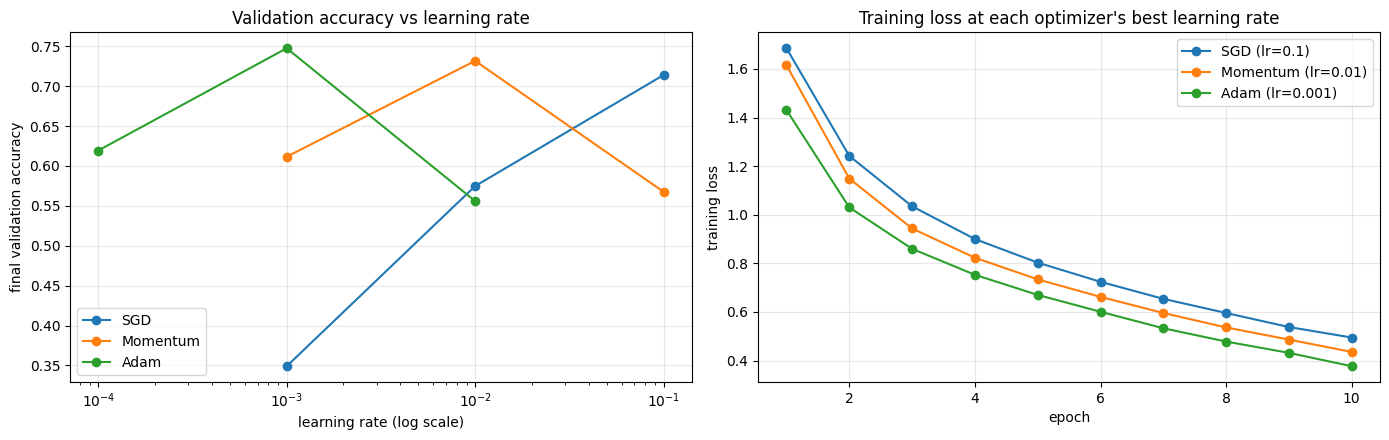

optimizer       lr  final val acc  best val acc  final train loss
SGD          0.001         0.3490        0.3490             1.870
SGD           0.01         0.5748        0.5748             1.130
SGD            0.1         0.7140        0.7140             0.495
Momentum     0.001         0.6116        0.6116             1.103
Momentum      0.01         0.7318        0.7456             0.436
Momentum       0.1         0.5676        0.5806             1.209
Adam        0.0001         0.6194        0.6194             1.054
Adam         0.001         0.7476        0.7556             0.377
Adam          0.01         0.5560        0.5618             1.212


In [36]:
def final_acc(h):
    return 0.10 if (h['diverged'] or not h['val_acc']) else h['val_acc'][-1]   # diverged counts as chance

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
best = {}
for name, lrs in grid.items():
    accs = [final_acc(results[f"{name}_lr{lr}"]) for lr in lrs]
    ax[0].semilogx(lrs, accs, 'o-', label=name)
    best[name] = lrs[int(np.argmax(accs))]
ax[0].set_xlabel('learning rate (log scale)'); ax[0].set_ylabel('final validation accuracy')
ax[0].set_title('Validation accuracy vs learning rate'); ax[0].legend(); ax[0].grid(alpha=0.3)

for name, lr in best.items():
    h = results[f"{name}_lr{lr}"]
    ax[1].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', label=f"{name} (lr={lr})")
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('training loss')
ax[1].set_title('Training loss at each optimizer\'s best learning rate'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'optimizer':<10}{'lr':>8}{'final val acc':>15}{'best val acc':>14}{'final train loss':>18}")
for name, lrs in grid.items():
    for lr in lrs:
        h = results[f"{name}_lr{lr}"]
        if h['diverged'] or not h['val_acc']:
            print(f"{name:<10}{lr:>8}{'diverged':>15}")
        else:
            print(f"{name:<10}{lr:>8}{h['val_acc'][-1]:>15.4f}{max(h['val_acc']):>14.4f}{h['train_loss'][-1]:>18.3f}")

#### Plot Interpretation:
At each optimizer's best learning rate, Adam reached the highest final validation accuracy (74.8%, $lr=0.001$), followed by Momentum (73.2%, $lr=0.01$) and SGD (71.4%, $lr=0.1$).
The 1.6% gap between Adam and Momentum is too small to call a clear winner from a single seed. This 114k-parameter CNN also far outperforms the 1.7M-parameter MLP from Task 1 (52%), showing the benefit of convolutions exploiting spatial structure.
<br/>

**Sensitivity:** All three optimizers are sensitive to the learning rate, and their best rates differ by about 100x (0.1 for SGD, 0.001 for Adam), so each must be tuned separately. Momentum at $lr=0.001$ trains almost identically to SGD at $lr=0.01$, consistent with the effective learning rate $\frac{lr}{1-\mu} = 10 \cdot lr$ for $\mu = 0.9$. Too small a rate makes training very slow (SGD at 0.001: 35%), although Adam remains reasonable at $10^{-4}$ because its step size does not depend on the gradient scale. Too large a rate (Momentum at 0.1, Adam at 0.01) makes the loss plateau near 1.21 with fluctuating validation accuracy. SGD's best rate lies at the edge of the grid, so its true optimum may be higher. <br/>


**Training loss:** At the best rates, Adam reduces the training loss fastest, especially in the
first epochs (1.43 vs 1.62 vs 1.69 after epoch 1). Its validation loss, however, starts rising
after epoch 6 while training loss keeps falling, an early sign of overfitting that motivates Task 3.

# Task 03: Regularization and Residual connections

(a) Train a small CNN with batch norm on 5k training images. Compare: baseline, weight decay, dropout, flip+crop, cutout, mixup, and all combined (implement cutout and mixup yourself). Tabulate train accuracy, validation accuracy, and their gap; plot the curves. <br/>


(b) Build CIFAR-style plain and residual networks of depth 6n +2 for depths 8, 20, and 56 (three stages, channels 16/32/64, global average pooling, batch norm, Kaiming initialization). The only difference between the two families is the shortcut. Plot the training loss versus epoch and explain.

## (a) Model, regularizers, and training function

## Task 3a: Regularization

With only 5k training images, the CNN can memorize the training set, creating a large gap
between training and validation accuracy. All models use batch normalization. We compare:

| Regularizer | Idea |
| :--- | :--- |
| **Weight decay** | Adds $\frac{\lambda}{2}\sum w^2$ to the loss, pulling weights toward zero (simpler functions). |
| **Dropout** | Randomly zeroes activations during training, so the network cannot rely on specific neurons. |
| **Flip + crop** | Random mirroring and small shifts; effectively enlarges the dataset. |
| **Cutout** | Masks a random 16x16 square, forcing the model to use the whole object. |
| **Mixup** | Trains on blends of two images and their labels, giving smoother decision boundaries. |
| **All combined** | Tests whether too much regularization causes underfitting. |

Train accuracy is measured on the **clean** training images in `model.eval()` mode, so augmentation
and mixup do not distort the gap.

In [37]:
class BNCNN(nn.Module):
    def __init__(self, dropout=0.0, num_classes=10):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2)
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))   # -> 128 x 4 x 4
        self.dropout = nn.Dropout(dropout)       # p=0 means no dropout
        self.classifier = nn.Linear(128 * 4 * 4, num_classes)

    def forward(self, x):
        x = self.features(x).flatten(1)
        return self.classifier(self.dropout(x))


class Cutout:
    """Zero out one random size x size square. Applied to a normalized tensor, so 0 = the mean pixel."""
    def __init__(self, size=16):
        self.size = size

    def __call__(self, img):                 # img: tensor (C, H, W)
        img = img.clone()
        _, h, w = img.shape
        cy = torch.randint(h, (1,)).item()   # centre can be anywhere; the square is clipped at the borders
        cx = torch.randint(w, (1,)).item()
        half = self.size // 2
        # y1, y2, x1, x2 = the square's bounds, clipped to [0, h] and [0, w]
        y1, y2 = max(0, cy - half), min(h, cy + half)
        x1, x2 = max(0, cx - half), min(w, cx + half)
        img[:, y1:y2, x1:x2] = 0.0
        return img


def build_train_tf(aug):
    """aug: list containing any of 'flip_crop', 'cutout'."""
    tfs = []
    if 'flip_crop' in aug:
        tfs += [T.RandomCrop(32, padding=4), T.RandomHorizontalFlip()]
    tfs += [T.ToTensor(), normalize]
    if 'cutout' in aug:
        tfs.append(Cutout(16))
    return T.Compose(tfs)


def get_clean_train_loader(n_train=5000):
    """Training images WITHOUT augmentation, for measuring train accuracy fairly."""
    ds = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=base_tf)
    return DataLoader(Subset(ds, train_idx[:n_train]), batch_size=512,
                      shuffle=False, num_workers=NUM_WORKERS)


def train_epoch_reg(model, loader, opt, mixup_alpha=0.0):
    model.train()
    total_loss, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        if mixup_alpha > 0:
            lam = float(np.random.beta(mixup_alpha, mixup_alpha))
            perm = torch.randperm(xb.size(0), device=device)   # partner image for each sample
            xb = lam * xb + (1 - lam) * xb[perm]
            logits = model(xb)
            loss = lam * F.cross_entropy(logits, yb) + (1 - lam) * F.cross_entropy(logits, yb[perm])
        else:
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total_loss += loss.item() * len(yb)
        n += len(yb)
    return total_loss / n                    # the training objective (includes mixup), not plain CE


m = BNCNN(dropout=0.5)
print("parameters:", sum(p.numel() for p in m.parameters()))
print("output shape:", m(torch.randn(2, 3, 32, 32)).shape)

parameters: 113962
output shape: torch.Size([2, 10])


### Look at the augmentations before training

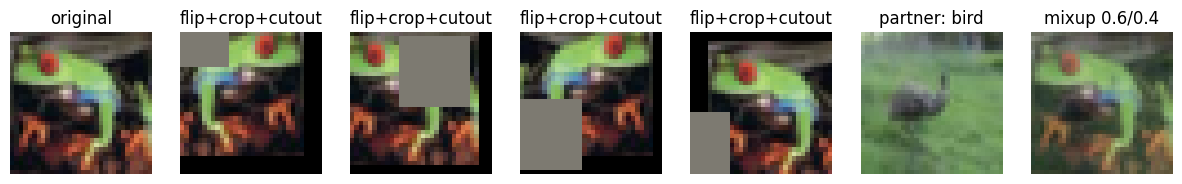

In [38]:
set_seed(0)
show_tf = build_train_tf(['flip_crop', 'cutout'])
ds_show = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=show_tf)
ds_clean = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=base_tf)

def to_img(t):
    return (t * std.view(3, 1, 1) + mean.view(3, 1, 1)).permute(1, 2, 0).clamp(0, 1)

idx0 = train_idx[0]
fig, axes = plt.subplots(1, 7, figsize=(15, 2.5))
axes[0].imshow(to_img(ds_clean[idx0][0])); axes[0].set_title('original')
for k in range(1, 5):
    axes[k].imshow(to_img(ds_show[idx0][0])); axes[k].set_title('flip+crop+cutout')

xa, ya = ds_clean[train_idx[0]]; xb_, yb_ = ds_clean[train_idx[1]]
lam = 0.6
axes[5].imshow(to_img(xb_)); axes[5].set_title(f'partner: {raw.classes[yb_]}')
axes[6].imshow(to_img(lam * xa + (1 - lam) * xb_))
axes[6].set_title(f'mixup {lam:.1f}/{1-lam:.1f}')
for a in axes: a.axis('off')
plt.show()

### Run all 7 Configurations

In [39]:
configs = {
    'baseline':     dict(),
    'weight_decay': dict(wd=5e-4),
    'dropout':      dict(dropout=0.5),
    'flip_crop':    dict(aug=['flip_crop']),
    'cutout':       dict(aug=['cutout']),
    'mixup':        dict(mixup=0.2),
    'all':          dict(wd=5e-4, dropout=0.5, aug=['flip_crop', 'cutout'], mixup=0.2),
}

def run_reg(cfg, epochs=60, seed=42, lr=0.01, n_train=5000):
    set_seed(seed)
    train_loader, val_loader = get_loaders(train_tf=build_train_tf(cfg.get('aug', [])),
                                           batch_size=128, n_train=n_train)
    clean_loader = get_clean_train_loader(n_train)
    model = BNCNN(dropout=cfg.get('dropout', 0.0)).to(device)
    opt = MySGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=cfg.get('wd', 0.0))
    hist = {'train_obj': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for ep in range(epochs):
        obj = train_epoch_reg(model, train_loader, opt, cfg.get('mixup', 0.0))
        _, tr_acc = eval_model(model, clean_loader)      # clean images, eval mode
        vl, va = eval_model(model, val_loader)
        for k, v in zip(hist, [obj, tr_acc, vl, va]):
            hist[k].append(v)
        if (ep + 1) % 10 == 0:
            print(f"  epoch {ep+1:2d} | train acc {tr_acc:.3f} | val acc {va:.3f} | gap {tr_acc - va:.3f}")
    return hist

results3a_path = os.path.join(RESULTS_DIR, 'task3a_results.json')
results3a = json.load(open(results3a_path)) if os.path.exists(results3a_path) else {}

for name, cfg in configs.items():
    if name in results3a:
        print(f"skip {name} (already done)"); continue
    print(f"=== {name} ===")
    t0 = time.time()
    results3a[name] = run_reg(cfg)
    with open(results3a_path, 'w') as fh:
        json.dump(results3a, fh)
    print(f"  took {time.time() - t0:.0f} s")

skip baseline (already done)
skip weight_decay (already done)
skip dropout (already done)
skip flip_crop (already done)
skip cutout (already done)
skip mixup (already done)
skip all (already done)


### Table and Plots

config          train acc   val acc      gap  best val
baseline           1.0000    0.6346   0.3654    0.6406
weight_decay       1.0000    0.6423   0.3577    0.6474
dropout            0.9942    0.6610   0.3332    0.6696
flip_crop          0.8484    0.7097   0.1386    0.7218
cutout             0.9938    0.6334   0.3604    0.6564
mixup              0.9996    0.5841   0.4154    0.6278
all                0.7062    0.6360   0.0703    0.6490


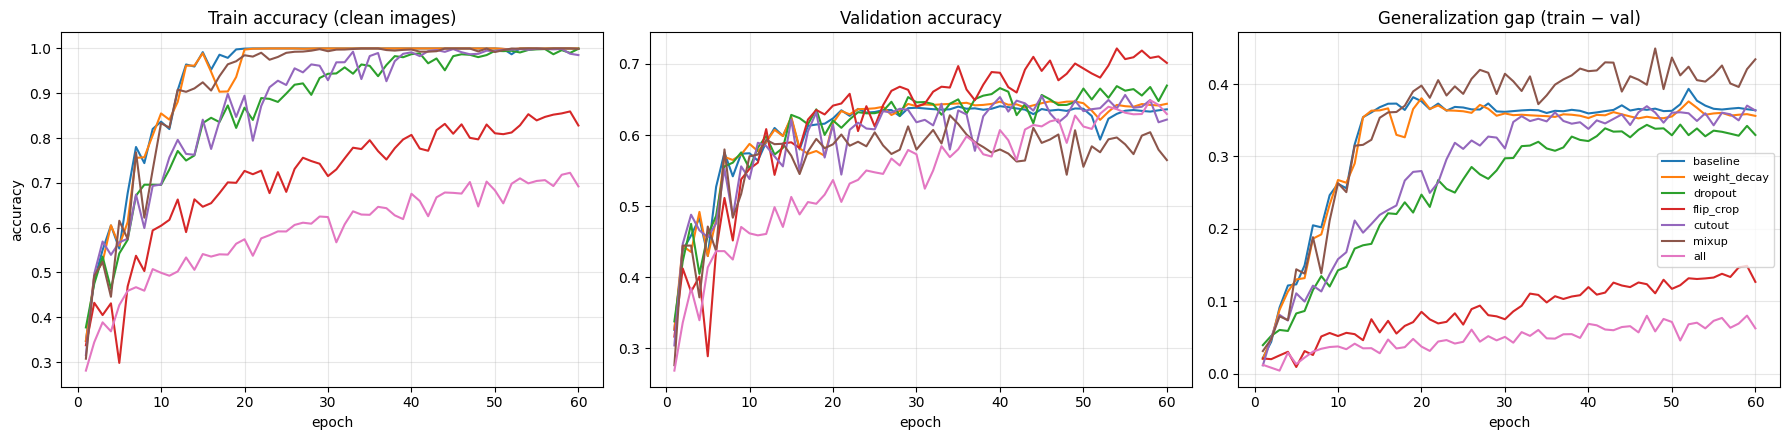

In [40]:
K = 5   # average over the last K epochs
print(f"{'config':<14}{'train acc':>11}{'val acc':>10}{'gap':>9}{'best val':>10}")
for name, h in results3a.items():
    tr = np.mean(h['train_acc'][-K:]); va = np.mean(h['val_acc'][-K:])
    print(f"{name:<14}{tr:>11.4f}{va:>10.4f}{tr - va:>9.4f}{max(h['val_acc']):>10.4f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for name, h in results3a.items():
    ep = range(1, len(h['val_acc']) + 1)
    ax[0].plot(ep, h['train_acc'], label=name)
    ax[1].plot(ep, h['val_acc'], label=name)
    ax[2].plot(ep, np.array(h['train_acc']) - np.array(h['val_acc']), label=name)
for a, t in zip(ax, ['Train accuracy (clean images)', 'Validation accuracy', 'Generalization gap (train − val)']):
    a.set_title(t); a.set_xlabel('epoch'); a.grid(alpha=0.3)
ax[0].set_ylabel('accuracy'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Interpretation:
All models were trained on 5k images for 60 epochs (SGD, momentum 0.9, lr 0.01, same seed);
values are averaged over the last 5 epochs. The baseline reaches 100% training accuracy by
about epoch 20 while validation accuracy plateaus at 63.5%, a gap of 0.37: the network
memorizes the small training set.

**Flip + crop** was by far the most effective (71.0% validation, +7.5 points; gap 0.14).
Since the model never sees the same image twice, it cannot simply memorize, and the
transformations match real variation in photos (position, left-right orientation).
Its curves are still rising at epoch 60, so more epochs would likely help further.
**Dropout** gave a modest gain (+2.6) by delaying memorization, but it is applied only before
the final layer. **Weight decay** had almost no effect (+0.8): with batch norm, the conv layers
are scale-invariant, so shrinking their weights does not simplify the function and mainly
changes the effective learning rate.

**Cutout** alone did not help: it delayed memorization but training accuracy still reached 99%,
since the unmasked part of each image is enough to memorize 5k images. **Mixup** reduced
validation accuracy to 58.4%. A likely reason is that $\alpha = 0.2$ gives mostly near-clean
images ($\lambda$ close to 0 or 1), so the model still memorized (99.96% train accuracy),
while the blended targets added noise to training.

**All combined** had the smallest gap (0.07) but underfit: training accuracy reached only 70.6%
and validation accuracy (63.6%) was no better than the baseline. A small gap is therefore not
the goal in itself, and regularizers do not simply add up; too much regularization prevents the
model from fitting the data within the epoch budget.

These conclusions come from a single seed, and validation accuracy fluctuates by 2–3 points
between epochs, so differences of 1–2 points are not reliable.

## (b) Residual Connections (ResNets)

**Core Equation:**
$$ y = F(x) + x $$
*(Where $F(x)$ represents the standard operations stack: conv → BN → ReLU → conv → BN stack)*

### Why Residual Shortcuts Improve Training
As networks become extremely deep, standard "plain" blocks struggle to optimize. The additive "$+ x$" shortcut solves two major mathematical bottlenecks:

Two reasons this helps:

1. **The identity becomes easy.** If a block isn't needed, it only has to push F(x) toward 0 (small weights), which is easy. A plain block has to learn the identity exactly through two convolutions and nonlinearities, which is hard.
2. The gradient gets a direct path. By the chain rule, $∂y/∂x = ∂F/∂x + I$. The identity term means the gradient from the loss can reach early layers through the shortcuts without being multiplied through every conv layer.

In [41]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.residual = residual
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.stride = stride
        self.pad = cout - cin                    # extra channels the shortcut must add

    def shortcut(self, x):
        """Option A: parameter-free. Subsample spatially, zero-pad the extra channels."""
        if self.stride != 1 or self.pad != 0:
            x = x[:, :, ::self.stride, ::self.stride]     # take every `stride`-th pixel in height and width
            x = F.pad(x, (0, 0, 0, 0, self.pad // 2, self.pad - self.pad // 2))   # zero-pad channels: pad // 2 in front, the rest at the back
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))     # conv1 -> bn1 -> ReLU
        out = self.bn2(self.conv2(out))     # conv2 -> bn2   (no ReLU yet)
        if self.residual:
            out = out + self.shortcut(x) # add the shortcut of the block's INPUT x
        return F.relu(out)


class CifarNet(nn.Module):
    def __init__(self, depth, residual, num_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0, "depth must be 6n + 2"
        n = (depth - 2) // 6
        self.conv = nn.Conv2d(3, 16, 3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(16)
        layers, cin = [], 16
        for cout, stride in [(16, 1), (32, 2), (64, 2)]:      # the three stages
            for i in range(n):
                layers.append(BasicBlock(cin, cout, stride if i == 0 else 1, residual))
                cin = cout
        self.blocks = nn.Sequential(*layers)
        self.fc = nn.Linear(64, num_classes)

        # Kaiming initialization
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        x = self.blocks(x)
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)       # global average pooling to (B, 64, 1, 1), then flatten to (B, 64)
        return self.fc(x)

### Sanity Check

In [42]:
for depth in [8, 20, 56]:
    for residual in [False, True]:
        net = CifarNet(depth, residual)
        n_layers = sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in net.modules())
        n_params = sum(p.numel() for p in net.parameters())
        out = net(torch.randn(2, 3, 32, 32))
        print(f"{'residual' if residual else 'plain':<9} depth {depth:2d} | weighted layers {n_layers:2d}"
              f" | params {n_params:>8,} | output {tuple(out.shape)}")

plain     depth  8 | weighted layers  8 | params   75,290 | output (2, 10)
residual  depth  8 | weighted layers  8 | params   75,290 | output (2, 10)
plain     depth 20 | weighted layers 20 | params  269,722 | output (2, 10)
residual  depth 20 | weighted layers 20 | params  269,722 | output (2, 10)
plain     depth 56 | weighted layers 56 | params  853,018 | output (2, 10)
residual  depth 56 | weighted layers 56 | params  853,018 | output (2, 10)


### Train all six

In [43]:
def run_depth(depth, residual, epochs=20, lr=0.05, seed=42):
    set_seed(seed)
    train_loader, val_loader = get_loaders(batch_size=128)
    model = CifarNet(depth, residual).to(device)
    opt = MySGD(model.parameters(), lr=lr, momentum=0.9)
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'diverged': False}
    for ep in range(epochs):
        tl, ta = train_epoch(model, train_loader, opt)
        if not math.isfinite(tl):
            hist['diverged'] = True; print(f"  diverged at epoch {ep+1}"); break
        vl, va = eval_model(model, val_loader)
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [tl, ta, vl, va]):
            hist[k].append(v)
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"  epoch {ep+1:2d} | train loss {tl:.4f} acc {ta:.3f} | val acc {va:.3f}")
    return hist

depths = [8, 20, 56]
def key3b(depth, residual):
    return f"{'res' if residual else 'plain'}{depth}"

results3b_path = os.path.join(RESULTS_DIR, 'task3b_results.json')
results3b = json.load(open(results3b_path)) if os.path.exists(results3b_path) else {}

for depth in depths:
    for residual in [False, True]:
        k = key3b(depth, residual)
        if k in results3b:
            print(f"skip {k} (already done)"); continue
        print(f"=== {k} ===")
        t0 = time.time()
        results3b[k] = run_depth(depth, residual)
        with open(results3b_path, 'w') as fh:
            json.dump(results3b, fh)
        print(f"  took {time.time() - t0:.0f} s")

skip plain8 (already done)
skip res8 (already done)
skip plain20 (already done)
skip res20 (already done)
skip plain56 (already done)
skip res56 (already done)


Plots and table

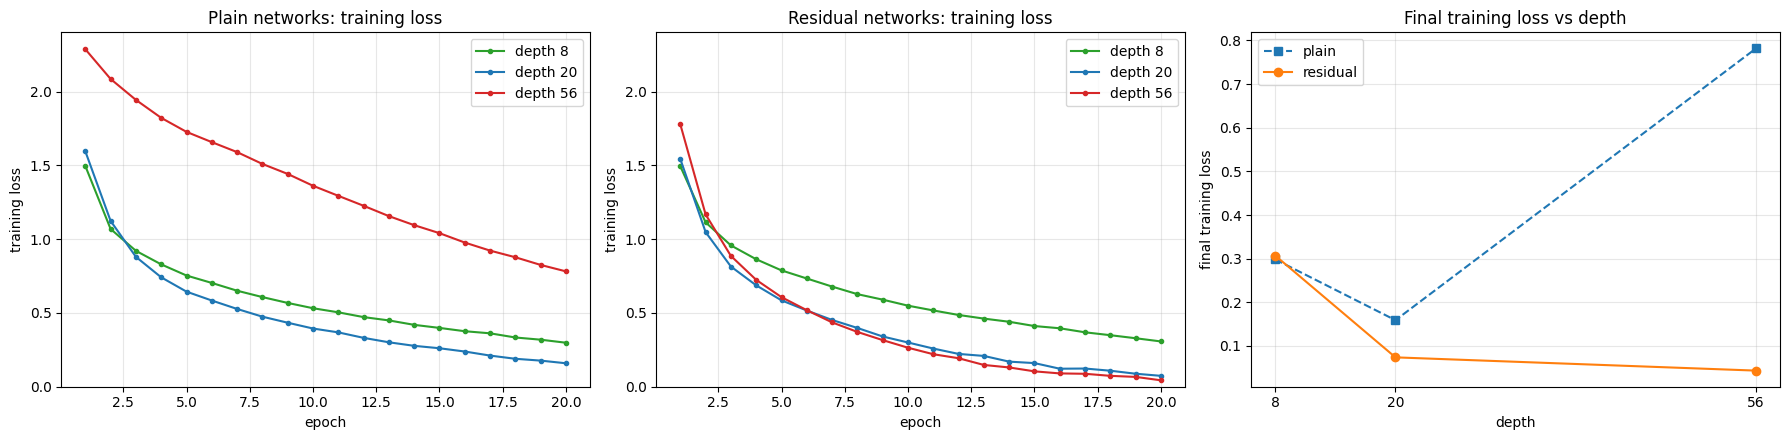

model        params  final train loss  final val acc
plain8       75,290            0.2981         0.7416
res8         75,290            0.3068         0.7332
plain20     269,722            0.1589         0.7854
res20       269,722            0.0738         0.7628
plain56     853,018            0.7817         0.5894
res56       853,018            0.0434         0.7182


In [44]:
colors = {8: 'tab:green', 20: 'tab:blue', 56: 'tab:red'}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for depth in depths:
    for residual, a in [(False, ax[0]), (True, ax[1])]:
        h = results3b[key3b(depth, residual)]
        a.plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', ms=3,
               color=colors[depth], label=f'depth {depth}')
ymax = max(max(h['train_loss']) for h in results3b.values())
for a, t in zip(ax[:2], ['Plain networks', 'Residual networks']):
    a.set_title(f'{t}: training loss'); a.set_xlabel('epoch'); a.set_ylabel('training loss')
    a.set_ylim(0, ymax * 1.05); a.legend(); a.grid(alpha=0.3)

for residual, style in [(False, 's--'), (True, 'o-')]:
    finals = [results3b[key3b(d, residual)]['train_loss'][-1] for d in depths]
    ax[2].plot(depths, finals, style, label='residual' if residual else 'plain')
ax[2].set_xticks(depths); ax[2].set_xlabel('depth'); ax[2].set_ylabel('final training loss')
ax[2].set_title('Final training loss vs depth'); ax[2].legend(); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'model':<9}{'params':>10}{'final train loss':>18}{'final val acc':>15}")
for depth in depths:
    for residual in [False, True]:
        k = key3b(depth, residual); h = results3b[k]
        n_params = sum(p.numel() for p in CifarNet(depth, residual).parameters())
        print(f"{k:<9}{n_params:>10,}{h['train_loss'][-1]:>18.4f}{h['val_acc'][-1]:>15.4f}")

#### Results Explanation:

**Plain networks degrade with depth.** Going from 8 to 20 layers lowers the final training loss (0.30 to 0.16), but the 56-layer network is far worse (0.78), even worse than the 8-layer one.
In its first epoch its loss (2.29) is close to $\ln 10 \approx 2.30$, the loss of random guessing. Since this is the *training* loss, the problem is not overfitting: SGD cannot optimize the deep plain network, even though it could in principle represent everything the 20-layer network does. This is the degradation problem.

**Residual networks improve with depth** (0.31, 0.074, 0.043 for depths 8, 20, 56). With $y = F(x) + x$, a block only has to push $F$ toward zero to act as an identity, and in the backward pass $\frac{\partial y}{\partial x} = \frac{\partial F}{\partial x} + I$, so gradients reach early layers directly through the shortcuts. The benefit grows with depth: at depth 8 the two families
are almost identical, at depth 20 the residual loss is about 2x lower, and at depth 56 about 18x lower.

Lower training loss did not always mean higher validation accuracy (res20: 76.3% vs plain20: 78.5%), because these runs used no regularization and the best-fitting networks overfit the most. The plain56 loss is still decreasing at epoch 20, so longer training would narrow the gap, but within the same budget it remains far behind.

# Task 04 - CNN (Optional)
Design the best CNN you can with at most 500k parameters and at most 20 training epochs. Tune on the
validation split. Report an ablation of at least three design choices (e.g., shortcut, augmentation, weight decay,
optimizer), and the test accuracy of your final model, evaluated once.

### Schedule, augmentation, and the training function

In [45]:
def warmup_cosine(step, total_steps, peak_lr, warmup_frac=0.15):
    warmup = max(1, int(warmup_frac * total_steps))
    if step < warmup:
        return peak_lr * (step + 1) / warmup                       # linear warmup
    progress = (step - warmup) / max(1, total_steps - warmup)      # 0 -> 1
    return peak_lr * 0.5 * (1 + math.cos(math.pi * progress))      # cosine decay to 0

aug_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor(), normalize])

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def run_task4(cfg, epochs=20, peak_lr=0.1, batch_size=128, seed=42, ckpt_path=None):
    set_seed(seed)
    train_loader, val_loader = get_loaders(train_tf=aug_tf if cfg['aug'] else base_tf,
                                           batch_size=batch_size)
    model = CifarNet(cfg['depth'], cfg['residual']).to(device)
    n_params = count_params(model)
    assert n_params <= 500_000, f"too many parameters: {n_params:,}"
    opt = MySGD(model.parameters(), lr=peak_lr, momentum=0.9, weight_decay=cfg['wd'])

    total_steps = epochs * len(train_loader)
    if cfg['schedule'] == 'cosine':
        lr_fn = lambda s: warmup_cosine(s, total_steps, peak_lr)
    else:
        lr_fn = lambda s: peak_lr

    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'params': n_params}
    step = 0
    for ep in range(epochs):
        model.train()
        tot, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            for g in opt.param_groups:
                g['lr'] = lr_fn(step)                    # update the learning rate every batch
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            step += 1
            tot += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
        if not math.isfinite(tot):
            print(f"  diverged at epoch {ep+1}"); break
        vl, va = eval_model(model, val_loader)
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [tot / n, correct / n, vl, va]):
            hist[k].append(v)
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"  epoch {ep+1:2d} | lr {lr_fn(step - 1):.4f} | train loss {tot/n:.4f} acc {correct/n:.3f}"
                  f" | val acc {va:.4f}")

    if ckpt_path is not None:
        torch.save(model.state_dict(), ckpt_path)       # keep the weights for the final test
    return hist

Schedule Check

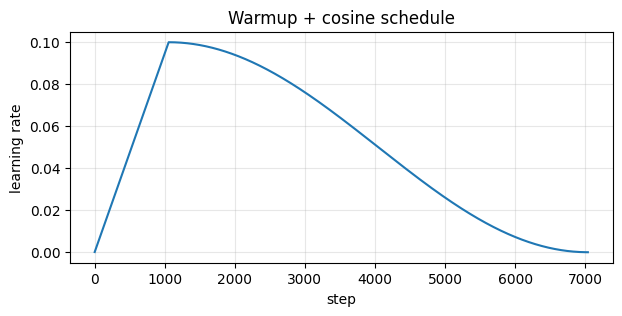

In [46]:
steps = 20 * 352                       # 20 epochs x 352 batches per epoch
plt.figure(figsize=(7, 3))
plt.plot([warmup_cosine(s, steps, 0.1) for s in range(steps)])
plt.xlabel('step'); plt.ylabel('learning rate'); plt.title('Warmup + cosine schedule'); plt.grid(alpha=0.3)
plt.show()

Tuning (depth 20 vs 32), and the ablations

In [47]:
results4_path = os.path.join(RESULTS_DIR, 'task4_results.json')
results4 = json.load(open(results4_path)) if os.path.exists(results4_path) else {}

def run_and_save(name, cfg, save_ckpt=False):
    if name in results4:
        print(f"skip {name} (already done)"); return
    print(f"=== {name} ===")
    t0 = time.time()
    ckpt = os.path.join(RESULTS_DIR, f'task4_{name}.pt') if save_ckpt else None
    results4[name] = run_task4(cfg, ckpt_path=ckpt)
    results4[name]['cfg'] = cfg
    with open(results4_path, 'w') as fh:
        json.dump(results4, fh)
    print(f"  took {time.time() - t0:.0f} s")

# --- Tuning on the validation split ---
full = dict(residual=True, aug=True, schedule='cosine', wd=5e-4)
for depth in [20, 32]:
    run_and_save(f'full_res{depth}', dict(full, depth=depth), save_ckpt=True)

best_depth = max([20, 32], key=lambda d: results4[f'full_res{d}']['val_acc'][-1])
print(f"\nChosen on validation: depth {best_depth}")

# --- Ablations: remove one design choice at a time ---
base = dict(full, depth=best_depth)
ablations = {
    'no_shortcut': dict(base, residual=False),
    'no_aug':      dict(base, aug=False),
    'const_lr':    dict(base, schedule='const'),
    'no_wd':       dict(base, wd=0.0),
}
for name, cfg in ablations.items():
    run_and_save(f'{name}_res{best_depth}', cfg)

skip full_res20 (already done)
skip full_res32 (already done)

Chosen on validation: depth 32
skip no_shortcut_res32 (already done)
skip no_aug_res32 (already done)
skip const_lr_res32 (already done)
skip no_wd_res32 (already done)


Ablation table and curves

run                           params  final val acc  best val acc   change
final model                  464,154         0.8936        0.8936   +0.00
no_shortcut                  464,154         0.8522        0.8538   -4.14
no_aug                       464,154         0.8628        0.8628   -3.08
const_lr                     464,154         0.7170        0.7722  -17.66
no_wd                        464,154         0.8826        0.8834   -1.10
full recipe, depth 20        269,722         0.8880        0.8880   -0.56


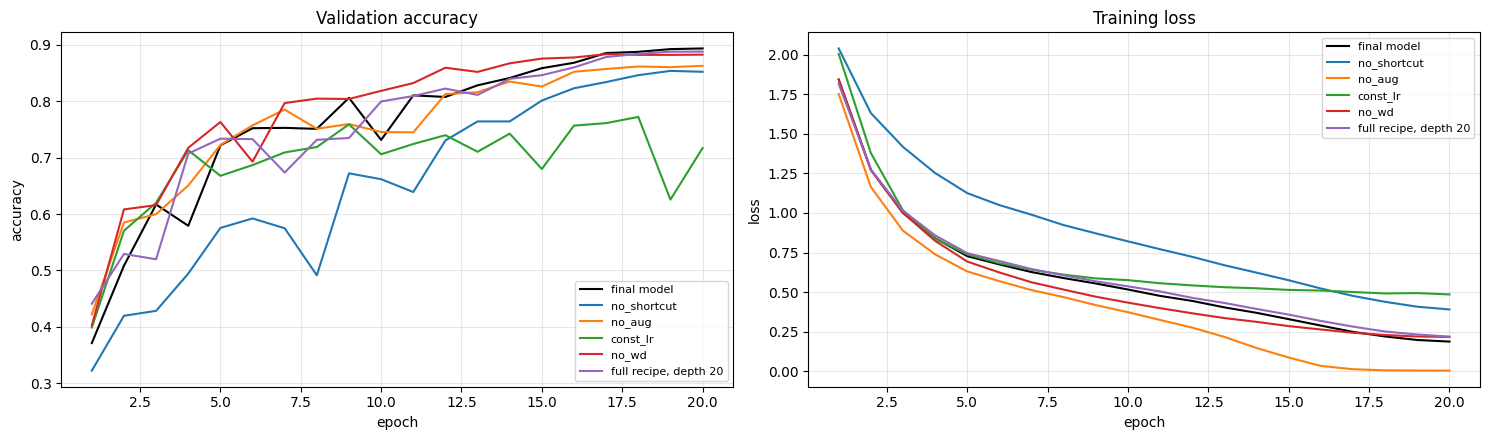

In [48]:
final_key = f'full_res{best_depth}'
ref = results4[final_key]['val_acc'][-1]
labels = {final_key: 'final model'}
labels.update({f'{n}_res{best_depth}': n for n in ablations})
other = 20 if best_depth == 32 else 32
labels[f'full_res{other}'] = f'full recipe, depth {other}'

print(f"{'run':<26}{'params':>10}{'final val acc':>15}{'best val acc':>14}{'change':>9}")
for key, lab in labels.items():
    h = results4[key]
    va = h['val_acc'][-1]
    print(f"{lab:<26}{h['params']:>10,}{va:>15.4f}{max(h['val_acc']):>14.4f}{(va - ref) * 100:>+8.2f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for key, lab in labels.items():
    h = results4[key]; ep = range(1, len(h['val_acc']) + 1)
    style = 'k-' if key == final_key else '-'
    ax[0].plot(ep, h['val_acc'], style, label=lab)
    ax[1].plot(ep, h['train_loss'], style, label=lab)
ax[0].set_title('Validation accuracy'); ax[0].set_ylabel('accuracy')
ax[1].set_title('Training loss'); ax[1].set_ylabel('loss')
for a in ax:
    a.set_xlabel('epoch'); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Test set

In [49]:
test_path = os.path.join(RESULTS_DIR, 'task4_test.json')
if os.path.exists(test_path):
    print("Test set was already evaluated (only once allowed):", json.load(open(test_path)))
else:
    test_set = torchvision.datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=base_tf)
    test_loader = DataLoader(test_set, batch_size=512, shuffle=False, num_workers=NUM_WORKERS)
    model = CifarNet(best_depth, residual=True).to(device)
    model.load_state_dict(torch.load(os.path.join(RESULTS_DIR, f'task4_full_res{best_depth}.pt'),
                                     map_location=device))
    test_loss, test_acc = eval_model(model, test_loader)
    result = {'model': f'full_res{best_depth}', 'params': count_params(model),
              'test_acc': test_acc, 'test_loss': test_loss}
    with open(test_path, 'w') as fh:
        json.dump(result, fh)
    print(f"Final model: ResNet-{best_depth}, {count_params(model):,} parameters")
    print(f"TEST accuracy: {test_acc:.4f}")

Test set was already evaluated (only once allowed): {'model': 'full_res32', 'params': 464154, 'test_acc': 0.8975, 'test_loss': 0.3139350115776062}


#### Final model and ablation:
**Final model:** ResNet-32 (464,154 params), flip + crop, SGD (momentum 0.9, wd 5e-4), batch 128, 20 epochs, warmup + cosine lr (peak 0.1).
- Depth chosen on validation: ResNet-32 (89.36%) vs ResNet-20 (88.80%).
- Cutout and mixup left out: no benefit in Task 3(a), risk of underfitting in 20 epochs.

**Ablation** (one choice removed at a time):

| Removed | Val acc change | Reason |
| :--- | :---: | :--- |
| LR schedule (constant 0.1) | -17.7 | Loss plateaus, accuracy oscillates (as in 2c); no decay to settle into a minimum |
| Residual shortcut | -4.1 | Slower training (loss 0.39 vs 0.19), degradation problem (3b) |
| Augmentation | -3.1 | Training loss → 0, memorization (3a) |
| Weight decay | -1.1 | Small effect; ahead early, overtaken in the final epochs |

- The schedule matters most under a fixed epoch budget. Note that the constant rate equals the peak
  rate, so part of the drop comes from the rate being too high late in training.
- Single seed: differences of about 1 point or less should be treated with caution.

**Test accuracy (evaluated once): 89.75%**, close to validation (89.36%), within sampling noise,
so the validation split was a reliable guide.